# Hospital Stay Prediction — Project Documentation

## Project Overview
This notebook explores a healthcare dataset and builds multiclass machine-learning models to predict the `Stay` category from hospital- and patient-related features.

## Workflow
1. Load and inspect the dataset.
2. Clean missing values and standardize selected category labels.
3. Explore categorical and numerical features.
4. Cap extreme values in selected numerical columns.
5. Separate predictors and target, then create a stratified train/test split.
6. Encode features and investigate class-balancing methods.
7. Train and evaluate several classification models.
8. Compare metrics, inspect feature importance, and summarize challenges and conclusions.

**Documentation note:** Explanatory Markdown cells have been added before and after code cells. The original code and its saved outputs have been preserved. Reported metrics should be checked against the actual outputs from the final notebook run.

### Importing Libraries

Import the libraries used for data handling, numerical operations, and plotting. Pandas and NumPy support data analysis, while Matplotlib and Seaborn are used for visualizations.

In [ ]:
 import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Loading the Dataset

Read the healthcare dataset from the CSV file path and display its dimensions and first few records. The `on_bad_lines='skip'` option skips malformed CSV lines.

In [ ]:
import pandas as pd

df = pd.read_csv(
    "/content/HealthCareAnalytics.csv",
    on_bad_lines="skip"
)

print(df.shape)
df.head()

(318438, 18)


,case_id,Hospital_code,Hospital_type_code,City_Code_Hospital,Hospital_region_code,Available_Extra_Rooms_in_Hospital,Department,Ward_Type,Ward_Facility_Code,Bed_Grade,patientid,City_Code_Patient,Type_of_Admission,Severity_of_Illness,Visitors_with_Patient,Age,Admission_Deposit,Stay
0,1,8,c,3,Z,3,radiotherapy,R,F,2.0,31397,7.0,Emergency,Extreme,2,51-60,4911,0-10
1,2,2,c,5,Z,2,radiotherapy,S,F,2.0,31397,7.0,Trauma,Extreme,2,51-60,5954,41-50
2,3,10,e,1,X,2,anesthesia,S,E,2.0,31397,7.0,Trauma,Extreme,2,51-60,4745,31-40
3,4,26,b,2,Y,2,radiotherapy,R,D,2.0,31397,7.0,Trauma,Extreme,2,51-60,7272,41-50
4,5,26,b,2,Y,2,radiotherapy,S,D,2.0,31397,7.0,Trauma,Extreme,2,51-60,5558,41-50


### Checking Dataset Structure

Use `df.info()` to review column names, non-null counts, data types, and memory usage.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 318438 entries, 0 to 318437
Data columns (total 18 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   case_id                            318438 non-null  int64  
 1   Hospital_code                      318438 non-null  int64  
 2   Hospital_type_code                 318438 non-null  object 
 3   City_Code_Hospital                 318438 non-null  int64  
 4   Hospital_region_code               318438 non-null  object 
 5   Available_Extra_Rooms_in_Hospital  318438 non-null  int64  
 6   Department                         318438 non-null  object 
 7   Ward_Type                          318438 non-null  object 
 8   Ward_Facility_Code                 318438 non-null  object 
 9   Bed_Grade                          318325 non-null  float64
 10  patientid                          318438 non-null  int64  
 11  City_Code_Patient                  3139

### Previewing Records

Display the first five rows to inspect the available fields and example values.

In [ ]:
df.head()

,case_id,Hospital_code,Hospital_type_code,City_Code_Hospital,Hospital_region_code,Available_Extra_Rooms_in_Hospital,Department,Ward_Type,Ward_Facility_Code,Bed_Grade,patientid,City_Code_Patient,Type_of_Admission,Severity_of_Illness,Visitors_with_Patient,Age,Admission_Deposit,Stay
0,1,8,c,3,Z,3,radiotherapy,R,F,2.0,31397,7.0,Emergency,Extreme,2,51-60,4911,0-10
1,2,2,c,5,Z,2,radiotherapy,S,F,2.0,31397,7.0,Trauma,Extreme,2,51-60,5954,41-50
2,3,10,e,1,X,2,anesthesia,S,E,2.0,31397,7.0,Trauma,Extreme,2,51-60,4745,31-40
3,4,26,b,2,Y,2,radiotherapy,R,D,2.0,31397,7.0,Trauma,Extreme,2,51-60,7272,41-50
4,5,26,b,2,Y,2,radiotherapy,S,D,2.0,31397,7.0,Trauma,Extreme,2,51-60,5558,41-50


### Inspecting the Case Identifier

Display the last values of `case_id` to inspect the identifier range.

In [ ]:
df["case_id"].tail()

,case_id
318433,318434
318434,318435
318435,318436
318436,318437
318437,318438


### Checking the Case Identifier Range

Check how many rows have `case_id` values greater than 318438.

In [ ]:
df[df["case_id"] > 318438].shape

(0, 18)

### Checking Missing Values

Count missing values in each column to identify fields that need cleaning.

In [ ]:
df.isnull().sum()

,0
case_id,0
Hospital_code,0
Hospital_type_code,0
City_Code_Hospital,0
Hospital_region_code,0
Available_Extra_Rooms_in_Hospital,0
Department,0
Ward_Type,0
Ward_Facility_Code,0
Bed_Grade,113


### Checking Duplicate Rows

Count fully duplicated rows in the dataset.

In [ ]:
df.duplicated().sum()

np.int64(0)

### Confirming Dataset Dimensions

Display the number of rows and columns in the current dataset.

In [ ]:
df.shape

(318438, 18)

### Finding Imputation Values

Calculate the mode of `Bed_Grade` and `City_Code_Patient` to identify the most frequent values for filling missing entries.

In [ ]:
print("Bed_Grade mode:", df["Bed_Grade"].mode()[0])
print("City_Code_Patient mode:", df["City_Code_Patient"].mode()[0])

Bed_Grade mode: 2.0
City_Code_Patient mode: 8.0


### Filling Missing Values

Replace missing values in `Bed_Grade` and `City_Code_Patient` with their respective modes, then print missing-value counts again.

In [ ]:
df["Bed_Grade"] = df["Bed_Grade"].fillna(df["Bed_Grade"].mode()[0])
df["City_Code_Patient"] = df["City_Code_Patient"].fillna(df["City_Code_Patient"].mode()[0])

print(df.isnull().sum())

case_id                              0
Hospital_code                        0
Hospital_type_code                   0
City_Code_Hospital                   0
Hospital_region_code                 0
Available_Extra_Rooms_in_Hospital    0
Department                           0
Ward_Type                            0
Ward_Facility_Code                   0
Bed_Grade                            0
patientid                            0
City_Code_Patient                    0
Type_of_Admission                    0
Severity_of_Illness                  0
Visitors_with_Patient                0
Age                                  0
Admission_Deposit                    0
Stay                                 0
dtype: int64


### Investigating the 'Nov-20' Value

Count the occurrences of the value `Nov-20` in `Age` and `Stay` before changing it.

In [ ]:
print("Age - Nov-20:", (df["Age"] == "Nov-20").sum())
print("Stay - Nov-20:", (df["Stay"] == "Nov-20").sum())

Age - Nov-20: 16768
Stay - Nov-20: 78139


### Reviewing Age and Stay Categories

Display frequency counts for the `Age` and `Stay` columns to inspect their category labels and distributions.

In [ ]:
print("Age values:")
print(df["Age"].value_counts())

print("\nStay values:")
print(df["Stay"].value_counts())

Age values:
Age
41-50     63749
31-40     63639
51-60     48514
21-30     40843
71-80     35792
61-70     33687
Nov-20    16768
81-90      7890
0-10       6254
91-100     1302
Name: count, dtype: int64

Stay values:
Stay
21-30                 87491
Nov-20                78139
31-40                 55159
51-60                 35018
0-10                  23604
41-50                 11743
71-80                 10254
More than 100 Days     6683
81-90                  4838
91-100                 2765
61-70                  2744
Name: count, dtype: int64


### Correcting Category Labels

Replace `Nov-20` with `11-20` in the `Age` and `Stay` columns, then verify that the original string no longer appears.

In [ ]:
df["Age"] = df["Age"].replace("Nov-20", "11-20")
df["Stay"] = df["Stay"].replace("Nov-20", "11-20")

print("Age Nov-20:", (df["Age"] == "Nov-20").sum())
print("Stay Nov-20:", (df["Stay"] == "Nov-20").sum())

Age Nov-20: 0
Stay Nov-20: 0


### Inspecting Identifier Columns

Display sample values and unique counts for `case_id` and `patientid`.

In [ ]:
print(df[["case_id", "patientid"]].head())
print("\nUnique case_id:", df["case_id"].nunique())
print("Unique patientid:", df["patientid"].nunique())

   case_id  patientid
0        1      31397
1        2      31397
2        3      31397
3        4      31397
4        5      31397

Unique case_id: 318438
Unique patientid: 92017


### Removing Identifier Columns

Drop `case_id` and `patientid` from the working dataframe, then display the resulting shape and column names.

In [ ]:
df = df.drop(columns=["case_id", "patientid"])

print(df.shape)
print(df.columns.tolist())

(318438, 16)
['Hospital_code', 'Hospital_type_code', 'City_Code_Hospital', 'Hospital_region_code', 'Available_Extra_Rooms_in_Hospital', 'Department', 'Ward_Type', 'Ward_Facility_Code', 'Bed_Grade', 'City_Code_Patient', 'Type_of_Admission', 'Severity_of_Illness', 'Visitors_with_Patient', 'Age', 'Admission_Deposit', 'Stay']


### Reviewing Data Types

Display the data type of each remaining column.

In [ ]:
df.dtypes

,0
Hospital_code,int64
Hospital_type_code,object
City_Code_Hospital,int64
Hospital_region_code,object
Available_Extra_Rooms_in_Hospital,int64
Department,object
Ward_Type,object
Ward_Facility_Code,object
Bed_Grade,float64
City_Code_Patient,float64


### Classifying Feature Types

Print the columns treated as categorical/code-based, ordinal/category-based, numerical, and the target variable.

In [ ]:
print("Categorical / Code Columns:")
print([
    "Hospital_code",
    "Hospital_type_code",
    "City_Code_Hospital",
    "Hospital_region_code",
    "Ward_Facility_Code",
    "City_Code_Patient",
    "Department",
    "Ward_Type",
    "Type_of_Admission"
])

print("\nOrdinal / Category Columns:")
print([
    "Bed_Grade",
    "Severity_of_Illness",
    "Age"
])

print("\nNumerical Columns:")
print([
    "Available_Extra_Rooms_in_Hospital",
    "Visitors_with_Patient",
    "Admission_Deposit"
])

print("\nTarget:")
print("Stay")

Categorical / Code Columns:
['Hospital_code', 'Hospital_type_code', 'City_Code_Hospital', 'Hospital_region_code', 'Ward_Facility_Code', 'City_Code_Patient', 'Department', 'Ward_Type', 'Type_of_Admission']

Ordinal / Category Columns:
['Bed_Grade', 'Severity_of_Illness', 'Age']

Numerical Columns:
['Available_Extra_Rooms_in_Hospital', 'Visitors_with_Patient', 'Admission_Deposit']

Target:
Stay


### Descriptive Statistics

Generate descriptive statistics for the dataframe using `describe().T`.

In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Hospital_code,318438.0,18.318841,8.633755,1.0,11.0,19.0,26.0,32.0
City_Code_Hospital,318438.0,4.771717,3.102535,1.0,2.0,5.0,7.0,13.0
Available_Extra_Rooms_in_Hospital,318438.0,3.197627,1.168171,0.0,2.0,3.0,4.0,24.0
Bed_Grade,318438.0,2.625585,0.873070,1.0,2.0,3.0,3.0,4.0
City_Code_Patient,318438.0,7.262506,4.712210,1.0,4.0,8.0,8.0,38.0
Visitors_with_Patient,318438.0,3.284099,1.764061,0.0,2.0,3.0,4.0,32.0
Admission_Deposit,318438.0,4880.749392,1086.776254,1800.0,4186.0,4741.0,5409.0,11008.0


### Reviewing Category Frequencies

Print the value counts for selected categorical columns, including the target `Stay`.

In [ ]:
categorical_cols = [
    "Hospital_type_code",
    "Hospital_region_code",
    "Department",
    "Ward_Type",
    "Ward_Facility_Code",
    "Type_of_Admission",
    "Severity_of_Illness",
    "Age",
    "Stay"
]

for col in categorical_cols:
    print(f"\n--- {col} ---")
    print(df[col].value_counts())


--- Hospital_type_code ---
Hospital_type_code
a    143425
b     68946
c     45928
e     24770
d     20389
f     10703
g      4277
Name: count, dtype: int64

--- Hospital_region_code ---
Hospital_region_code
X    133336
Y    122428
Z     62674
Name: count, dtype: int64

--- Department ---
Department
gynecology            249486
anesthesia             29649
radiotherapy           28516
TB & Chest disease      9586
surgery                 1201
Name: count, dtype: int64

--- Ward_Type ---
Ward_Type
R    127947
Q    106165
S     77794
P      5046
T      1477
U         9
Name: count, dtype: int64

--- Ward_Facility_Code ---
Ward_Facility_Code
F    112753
E     55351
D     51809
C     35463
B     35156
A     27906
Name: count, dtype: int64

--- Type_of_Admission ---
Type_of_Admission
Trauma       152261
Emergency    117676
Urgent        48501
Name: count, dtype: int64

--- Severity_of_Illness ---
Severity_of_Illness
Moderate    175843
Minor        85872
Extreme      56723
Name: count, dtype:

### Distribution of Hospital Stay

Plot the frequency of each `Stay` category, ordered from most common to least common.

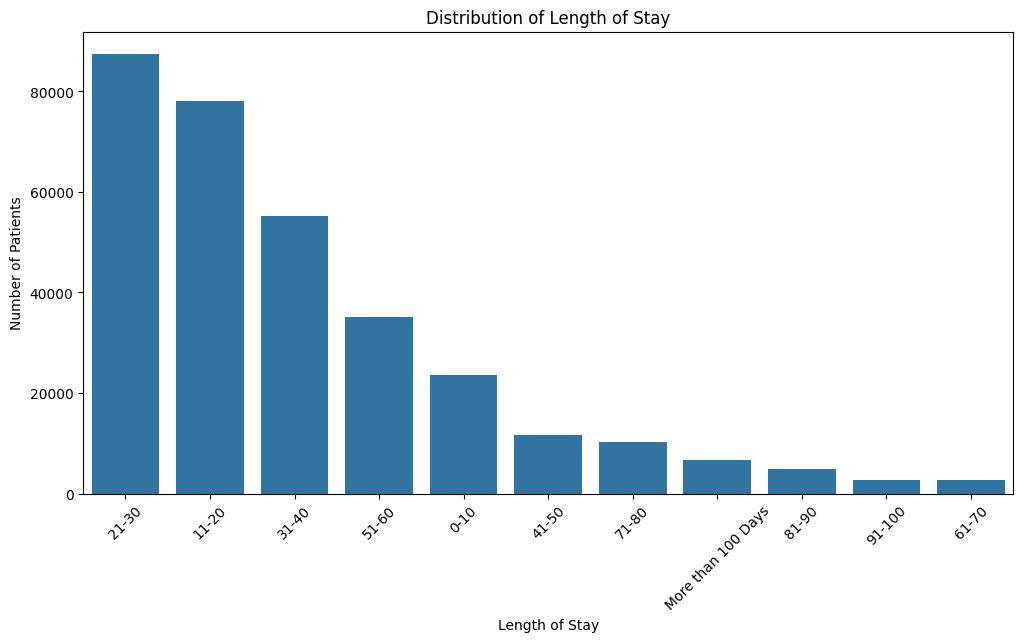

In [ ]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    x="Stay",
    order=df["Stay"].value_counts().index
)

plt.title("Distribution of Length of Stay")
plt.xlabel("Length of Stay")
plt.ylabel("Number of Patients")
plt.xticks(rotation=45)

plt.show()

### Categorical Feature Distributions

Create a count plot for each selected categorical feature to visualize the number of records in each category.

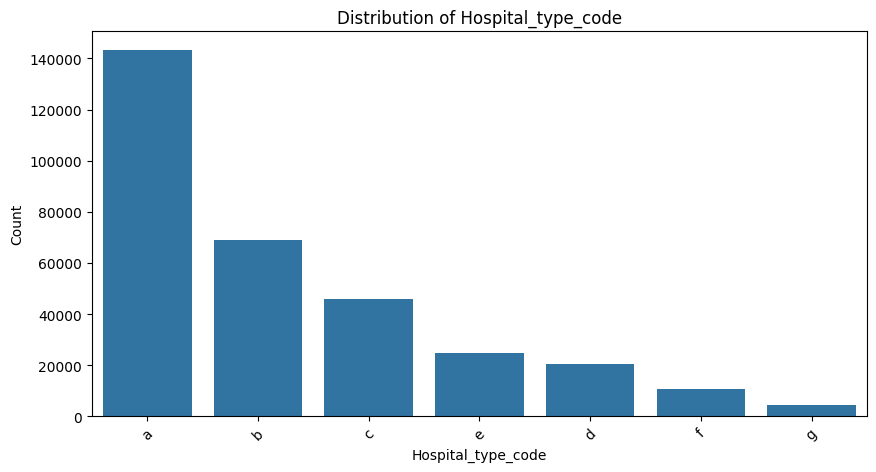

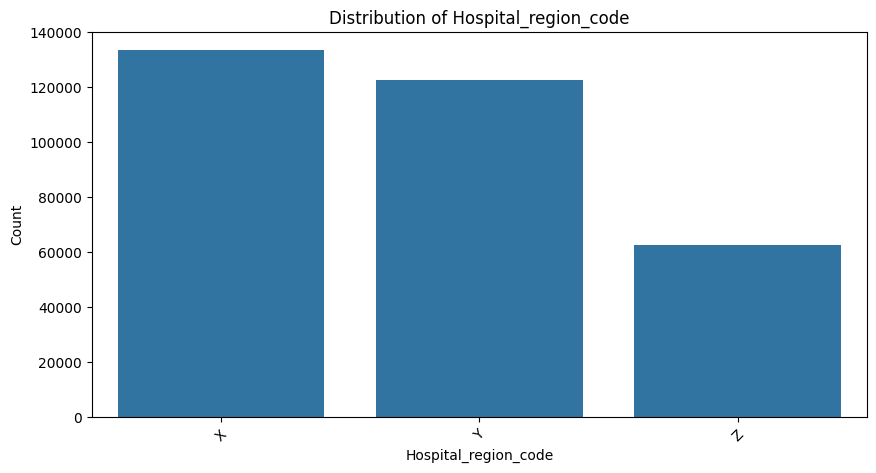

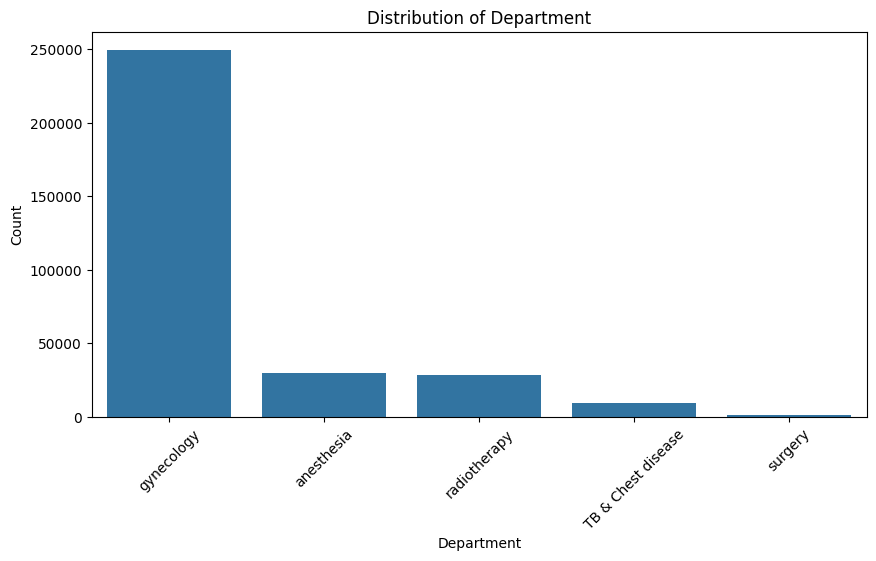

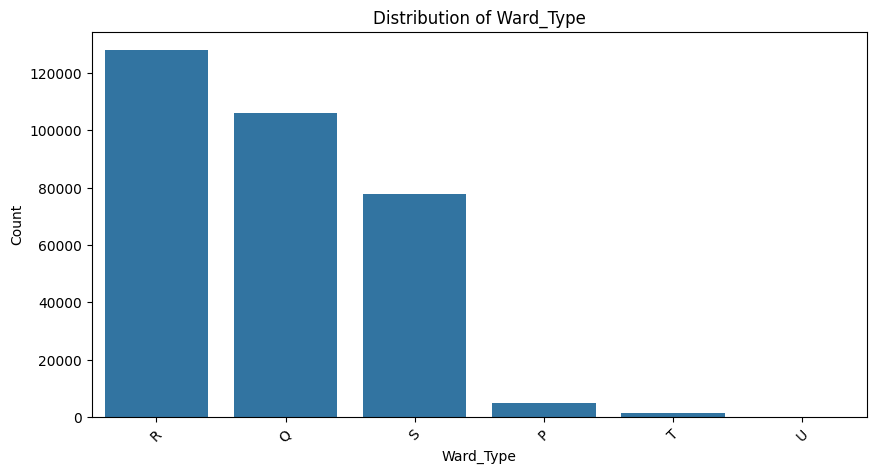

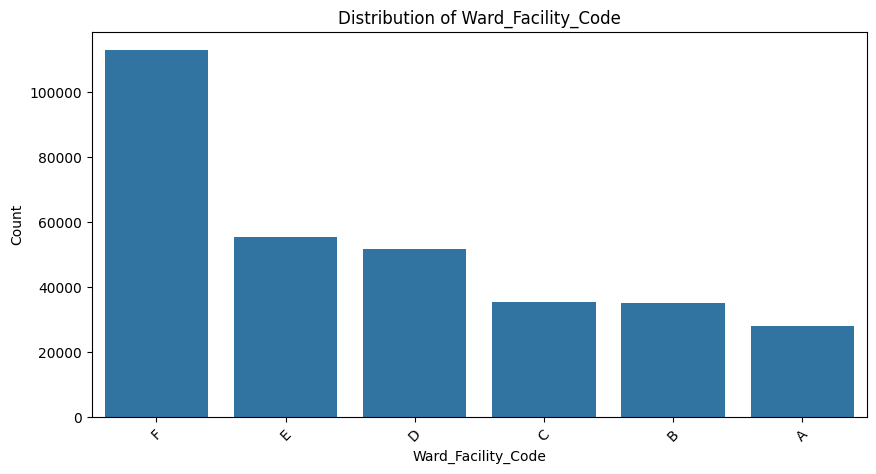

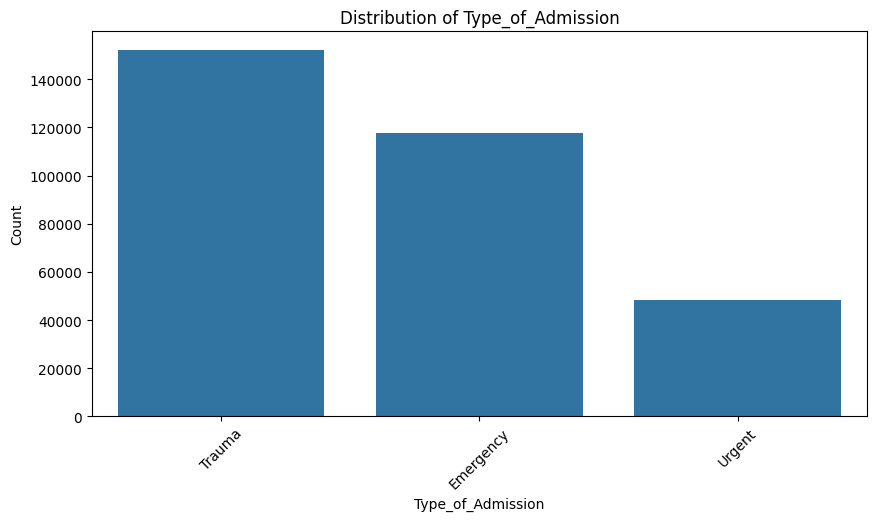

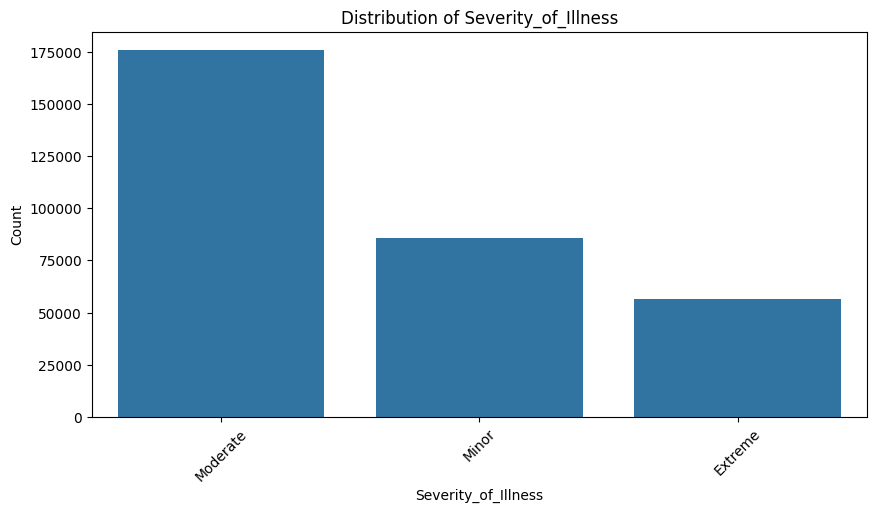

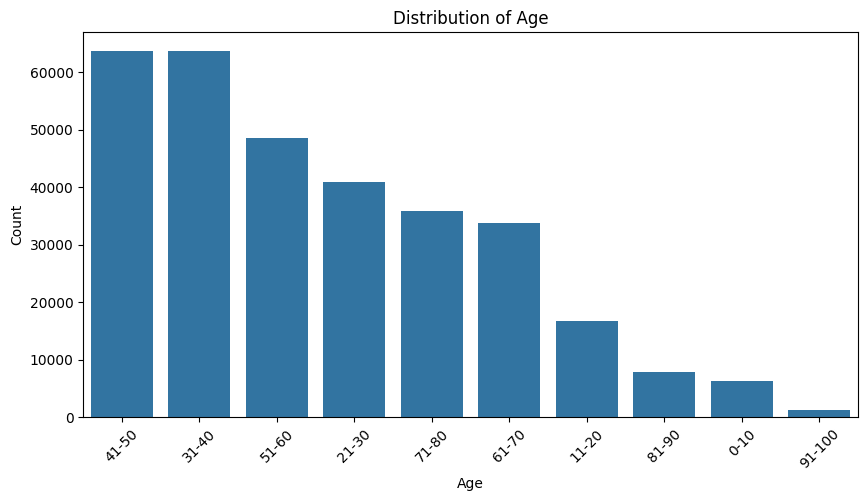

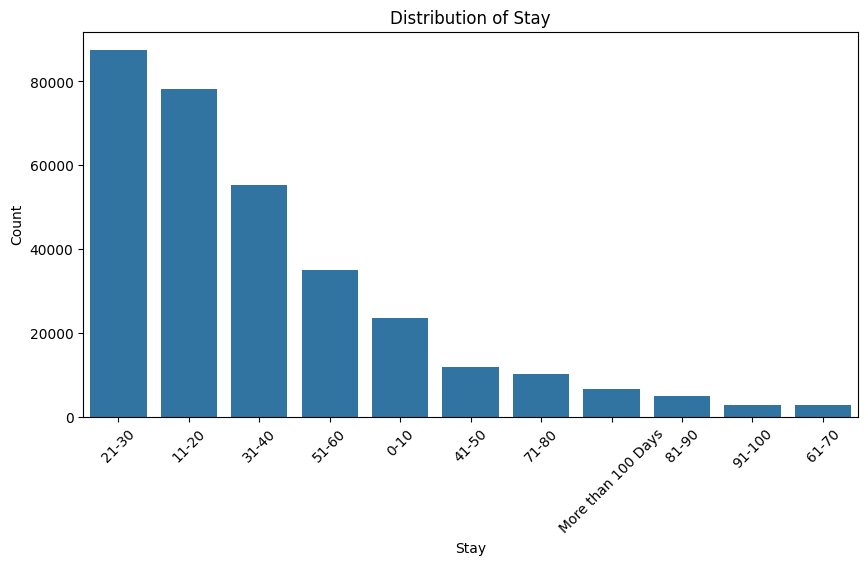

In [ ]:
categorical_cols = [
    "Hospital_type_code",
    "Hospital_region_code",
    "Department",
    "Ward_Type",
    "Ward_Facility_Code",
    "Type_of_Admission",
    "Severity_of_Illness",
    "Age",
    "Stay"
]

for col in categorical_cols:
    plt.figure(figsize=(10, 5))

    sns.countplot(
        data=df,
        x=col,
        order=df[col].value_counts().index
    )

    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.xticks(rotation=45)

    plt.show()

### Numerical Feature Distributions

Plot histograms with density curves for the selected numerical variables: available extra rooms, visitors with the patient, and admission deposit.

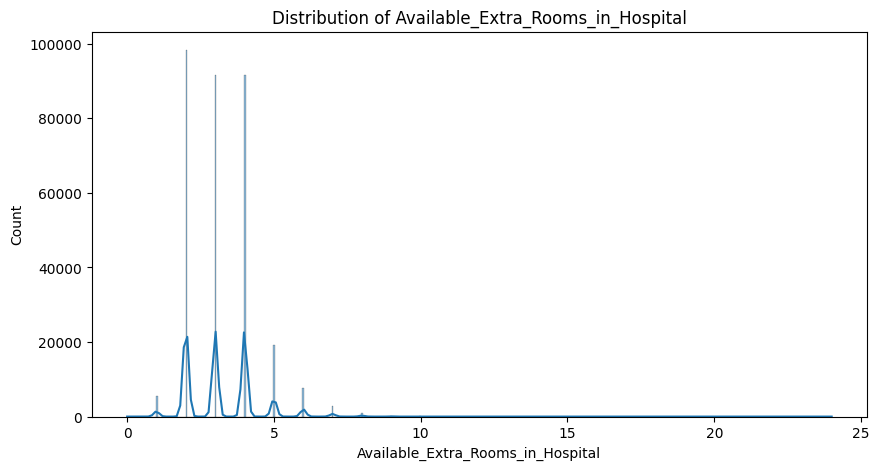

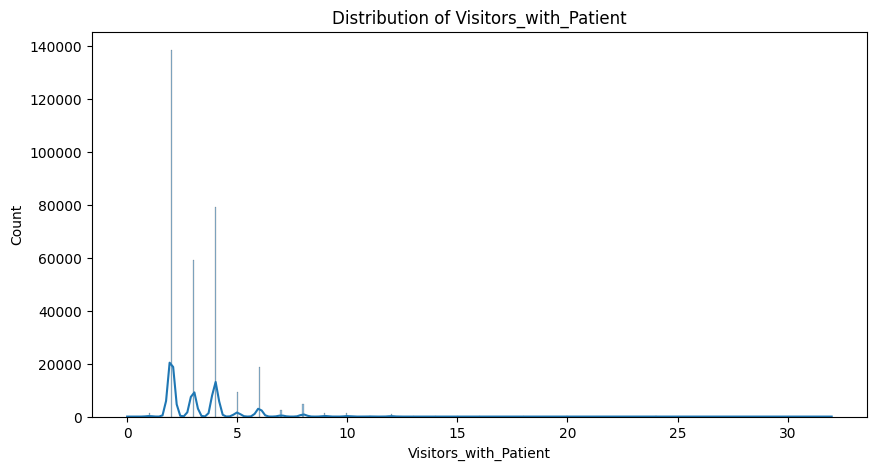

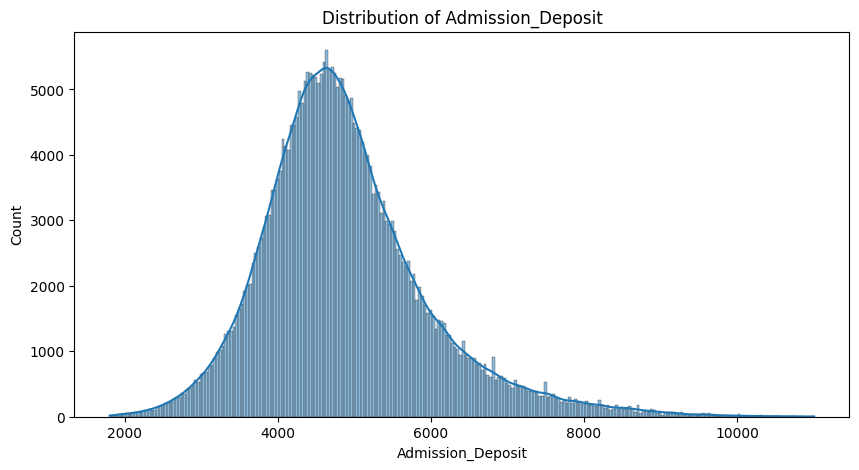

In [ ]:
numerical_cols = [
    "Available_Extra_Rooms_in_Hospital",
    "Visitors_with_Patient",
    "Admission_Deposit"
]

for col in numerical_cols:
    plt.figure(figsize=(10, 5))

    sns.histplot(data=df, x=col, kde=True)

    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Count")

    plt.show()

### Detecting Potential Outliers

Use boxplots to inspect the distribution and potential extreme values in each selected numerical feature.

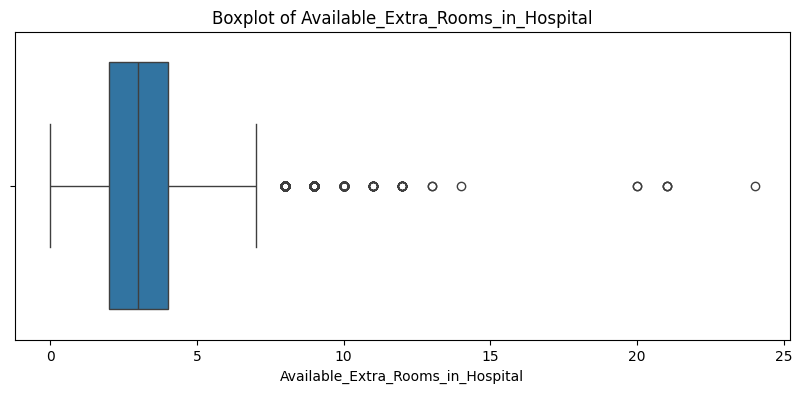

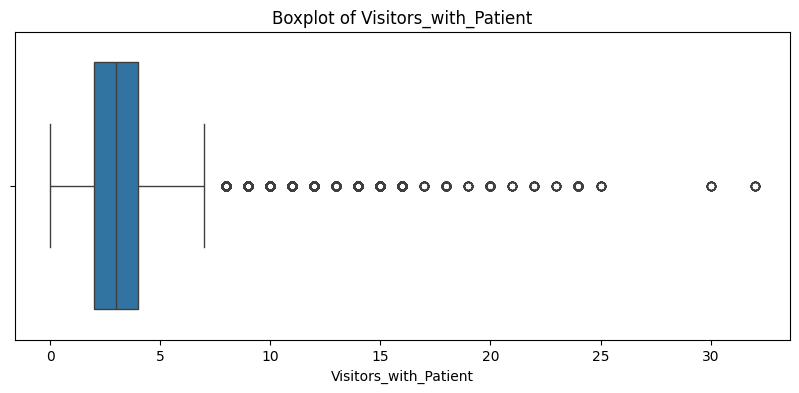

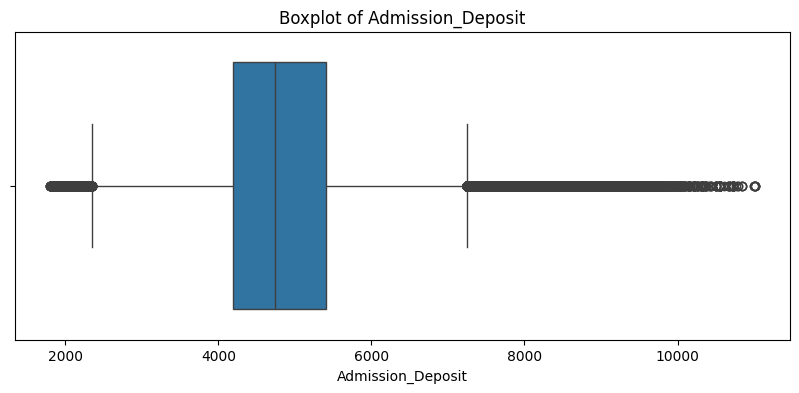

In [ ]:
for col in numerical_cols:
    plt.figure(figsize=(10, 4))

    sns.boxplot(x=df[col])

    plt.title(f"Boxplot of {col}")
    plt.xlabel(col)

    plt.show()

### Capping Extreme Numerical Values

Create `df_capped` as a copy of the dataframe and clip each selected numerical feature to its 1st and 99th percentiles.

In [ ]:
df_capped = df.copy()

for col in numerical_cols:
    lower_limit = df_capped[col].quantile(0.01)
    upper_limit = df_capped[col].quantile(0.99)

    df_capped[col] = df_capped[col].clip(
        lower=lower_limit,
        upper=upper_limit
    )

print("Original shape:", df.shape)
print("After clamping:", df_capped.shape)

Original shape: (318438, 16)
After clamping: (318438, 16)


### Reviewing Boxplots After Capping

Plot boxplots of the numerical features after percentile capping.

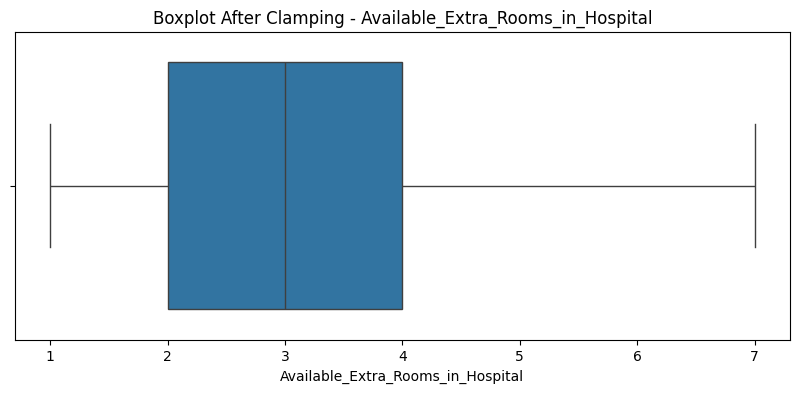

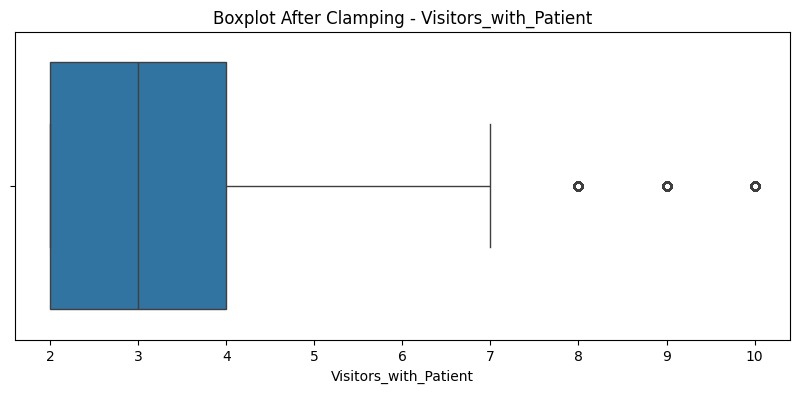

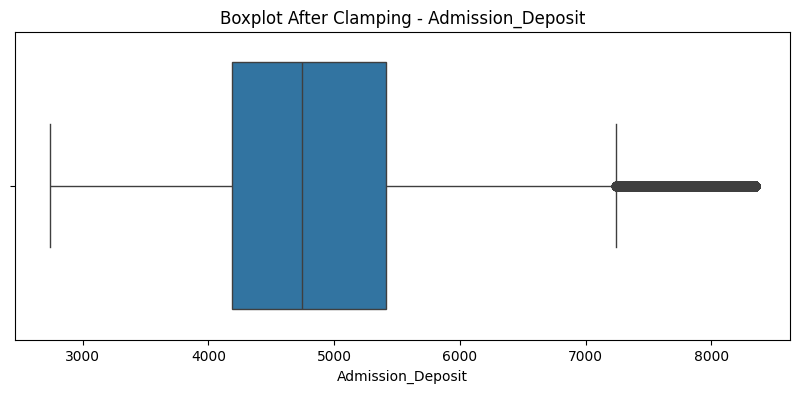

In [ ]:
for col in numerical_cols:
    plt.figure(figsize=(10, 4))

    sns.boxplot(x=df_capped[col])

    plt.title(f"Boxplot After Clamping - {col}")
    plt.xlabel(col)

    plt.show()

### Correlation Between Numerical Features

Calculate and display a correlation heatmap for the selected numerical features after capping.

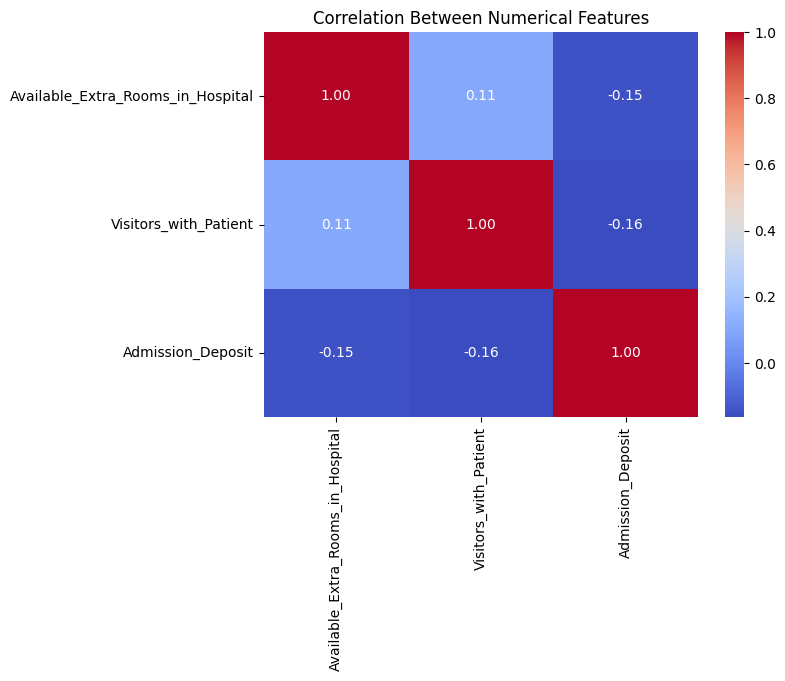

In [ ]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    df_capped[numerical_cols].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Numerical Features")
plt.show()

### Separating Predictors and Target

Create `X` from all columns except `Stay`, and set `y` to the target `Stay`. Print the shapes and target frequencies.

In [ ]:
X = df_capped.drop(columns=["Stay"])
y = df_capped["Stay"]

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nTarget classes:")
print(y.value_counts())

X shape: (318438, 15)
y shape: (318438,)

Target classes:
Stay
21-30                 87491
11-20                 78139
31-40                 55159
51-60                 35018
0-10                  23604
41-50                 11743
71-80                 10254
More than 100 Days     6683
81-90                  4838
91-100                 2765
61-70                  2744
Name: count, dtype: int64


### Train-Test Split

Split the data into 80% training and 20% testing subsets using stratification and a fixed random seed.

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (254750, 15)
X_test shape: (63688, 15)
y_train shape: (254750,)
y_test shape: (63688,)


# Preprocessing steps

### Defining Feature Groups

List the categorical, ordinal, and numerical predictors for preprocessing.

In [ ]:
categorical_cols = [
    "Hospital_code",
    "Hospital_type_code",
    "City_Code_Hospital",
    "Hospital_region_code",
    "City_Code_Patient",
    "Department",
    "Ward_Type",
    "Ward_Facility_Code",
    "Type_of_Admission"
]

ordinal_cols = [
    "Bed_Grade",
    "Severity_of_Illness",
    "Age"
]

numerical_cols = [
    "Available_Extra_Rooms_in_Hospital",
    "Visitors_with_Patient",
    "Admission_Deposit"
]

print("Categorical:", categorical_cols)
print("Ordinal:", ordinal_cols)
print("Numerical:", numerical_cols)

Categorical: ['Hospital_code', 'Hospital_type_code', 'City_Code_Hospital', 'Hospital_region_code', 'City_Code_Patient', 'Department', 'Ward_Type', 'Ward_Facility_Code', 'Type_of_Admission']
Ordinal: ['Bed_Grade', 'Severity_of_Illness', 'Age']
Numerical: ['Available_Extra_Rooms_in_Hospital', 'Visitors_with_Patient', 'Admission_Deposit']


### Importing Encoding Tools

Import `OneHotEncoder`, `OrdinalEncoder`, and `ColumnTransformer` from scikit-learn.

In [ ]:
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer

### Building the Preprocessing Transformer

Configure a ColumnTransformer to one-hot encode categorical features, ordinal-encode ordinal features, and pass numerical features through unchanged.

In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_cols),
        ("ordinal", OrdinalEncoder(), ordinal_cols),
        ("numerical", "passthrough", numerical_cols)
    ]
)

print("Preprocessor created successfully.")

Preprocessor created successfully.


### Transforming Train and Test Features

Fit the preprocessing transformer on the training features and apply the fitted transformer to both training and test features.

In [ ]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("X_train_processed shape:", X_train_processed.shape)
print("X_test_processed shape:", X_test_processed.shape)

X_train_processed shape: (254750, 116)
X_test_processed shape: (63688, 116)


### Importing SMOTENC

Import SMOTENC, an oversampling technique designed for datasets containing both categorical and numerical features.

In [ ]:
from imblearn.over_sampling import SMOTENC

### Creating a Training Copy for Resampling

Copy the original training features into `X_train_smote` before applying categorical encoding for SMOTENC.

In [ ]:
X_train_smote = X_train.copy()

print("X_train_smote shape:", X_train_smote.shape)


X_train_smote shape: (254750, 15)


### Checking Feature Positions

Print each feature's column index and name to help identify which positions correspond to categorical variables.

In [ ]:
for i, col in enumerate(X_train_smote.columns):
    print(i, col)

0 Hospital_code
1 Hospital_type_code
2 City_Code_Hospital
3 Hospital_region_code
4 Available_Extra_Rooms_in_Hospital
5 Department
6 Ward_Type
7 Ward_Facility_Code
8 Bed_Grade
9 City_Code_Patient
10 Type_of_Admission
11 Severity_of_Illness
12 Visitors_with_Patient
13 Age
14 Admission_Deposit


### Encoding Categorical Features for SMOTENC

Fit an OrdinalEncoder on the categorical columns in the training copy and transform those columns to numeric codes.

In [ ]:
smote_encoder = OrdinalEncoder(
    handle_unknown="use_encoded_value",
    unknown_value=-1
)

X_train_smote[categorical_cols] = smote_encoder.fit_transform(
    X_train_smote[categorical_cols]
)

print(X_train_smote.head())

        Hospital_code  Hospital_type_code  City_Code_Hospital  \
291926           25.0                 1.0                 1.0   
300988           16.0                 4.0                 0.0   
222241           10.0                 1.0                 1.0   
195018           15.0                 2.0                 2.0   
117009           24.0                 4.0                 0.0   

        Hospital_region_code  Available_Extra_Rooms_in_Hospital  Department  \
291926                   1.0                                  2         2.0   
300988                   0.0                                  4         2.0   
222241                   1.0                                  4         2.0   
195018                   2.0                                  5         1.0   
117009                   0.0                                  1         2.0   

        Ward_Type  Ward_Facility_Code  Bed_Grade  City_Code_Patient  \
291926        1.0                 3.0        4.0               

### Encoding Ordinal Features for SMOTENC

Fit an OrdinalEncoder on the designated ordinal columns in the training copy and transform them to numeric codes.

In [ ]:
ordinal_encoder = OrdinalEncoder(
    handle_unknown="use_encoded_value",
    unknown_value=-1
)

X_train_smote[ordinal_cols] = ordinal_encoder.fit_transform(
    X_train_smote[ordinal_cols]
)

print(X_train_smote.head())

        Hospital_code  Hospital_type_code  City_Code_Hospital  \
291926           25.0                 1.0                 1.0   
300988           16.0                 4.0                 0.0   
222241           10.0                 1.0                 1.0   
195018           15.0                 2.0                 2.0   
117009           24.0                 4.0                 0.0   

        Hospital_region_code  Available_Extra_Rooms_in_Hospital  Department  \
291926                   1.0                                  2         2.0   
300988                   0.0                                  4         2.0   
222241                   1.0                                  4         2.0   
195018                   2.0                                  5         1.0   
117009                   0.0                                  1         2.0   

        Ward_Type  Ward_Facility_Code  Bed_Grade  City_Code_Patient  \
291926        1.0                 3.0        3.0               

# Smotenc

### Selecting Categorical Feature Indices

Specify the column indices that SMOTENC should treat as categorical features.

In [ ]:
categorical_indices = [0, 1, 2, 3, 5, 6, 7, 9, 10]

### Applying SMOTENC

Fit SMOTENC to the encoded training features and training labels to create a resampled training set, then compare class counts and shapes before and after resampling.

In [ ]:
smote_nc = SMOTENC(
    categorical_features=categorical_indices,
    random_state=42
)

X_train_resampled, y_train_resampled = smote_nc.fit_resample(
    X_train_smote,
    y_train
)

print("Before SMOTENC:", y_train.value_counts().sort_index())
print("\nAfter SMOTENC:", y_train_resampled.value_counts().sort_index())
print("\nBefore shape:", X_train_smote.shape)
print("After shape:", X_train_resampled.shape)

Before SMOTENC: Stay
0-10                  18883
11-20                 62511
21-30                 69993
31-40                 44127
41-50                  9394
51-60                 28014
61-70                  2195
71-80                  8203
81-90                  3871
91-100                 2212
More than 100 Days     5347
Name: count, dtype: int64

After SMOTENC: Stay
0-10                  69993
11-20                 69993
21-30                 69993
31-40                 69993
41-50                 69993
51-60                 69993
61-70                 69993
71-80                 69993
81-90                 69993
91-100                69993
More than 100 Days    69993
Name: count, dtype: int64

Before shape: (254750, 15)
After shape: (769923, 15)


### Validating Resampled Data

Check the resampled feature matrix shape, total missing-value count, and data types.

In [ ]:
print("Shape:", X_train_resampled.shape)

print("\nMissing values:")
print(X_train_resampled.isnull().sum().sum())

print("\nData types:")
print(X_train_resampled.dtypes)

Shape: (769923, 15)

Missing values:
0

Data types:
Hospital_code                        float64
Hospital_type_code                   float64
City_Code_Hospital                   float64
Hospital_region_code                 float64
Available_Extra_Rooms_in_Hospital      int64
Department                           float64
Ward_Type                            float64
Ward_Facility_Code                   float64
Bed_Grade                            float64
City_Code_Patient                    float64
Type_of_Admission                    float64
Severity_of_Illness                  float64
Visitors_with_Patient                  int64
Age                                  float64
Admission_Deposit                      int64
dtype: object


### Training Logistic Regression

Initialize and fit a Logistic Regression classifier using the SMOTENC-resampled training features and labels.

In [ ]:
 from sklearn.linear_model import LogisticRegression

log_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

log_model.fit(X_train_resampled, y_train_resampled)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression(max_iter=1000, random_state=42)

### Preparing Test Features for the SMOTENC Models

Copy the test features and apply the encoders fitted on the training data to the corresponding categorical and ordinal columns.

In [ ]:
 X_test_smote = X_test.copy()

X_test_smote[categorical_cols] = smote_encoder.transform(
    X_test_smote[categorical_cols]
)

X_test_smote[ordinal_cols] = ordinal_encoder.transform(
    X_test_smote[ordinal_cols]
)

print(X_test_smote.shape)

(63688, 15)


### Evaluating Logistic Regression Accuracy

Predict stay categories for the test set and calculate Logistic Regression accuracy.

In [ ]:
 from sklearn.metrics import accuracy_score
 y_pred_log = log_model.predict(X_test_smote)

log_accuracy = accuracy_score(y_test, y_pred_log)

print("Logistic Regression Accuracy:", log_accuracy)

Logistic Regression Accuracy: 0.2291954528325587


### Evaluating Logistic Regression Metrics

Calculate accuracy, weighted precision, weighted recall, and weighted F1-score for Logistic Regression.

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

y_pred_log = log_model.predict(X_test_smote)

print("Logistic Regression - SMOTENC")
print("Accuracy :", accuracy_score(y_test, y_pred_log))
print("Precision:", precision_score(y_test, y_pred_log, average="weighted", zero_division=0))
print("Recall   :", recall_score(y_test, y_pred_log, average="weighted", zero_division=0))
print("F1-score :", f1_score(y_test, y_pred_log, average="weighted", zero_division=0))

Logistic Regression - SMOTENC
Accuracy : 0.2291954528325587
Precision: 0.30344813886197297
Recall   : 0.2291954528325587
F1-score : 0.24611615221660899


### Training a Decision Tree

Initialize and fit a Decision Tree classifier using the resampled training data.

In [ ]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(
    random_state=42
)

dt_model.fit(X_train_resampled, y_train_resampled)

DecisionTreeClassifier(random_state=42)

### Evaluating Decision Tree Accuracy

Predict the test labels and calculate the Decision Tree accuracy.

In [ ]:
y_pred_dt = dt_model.predict(X_test_smote)

dt_accuracy = accuracy_score(y_test, y_pred_dt)

print("Decision Tree Accuracy:", dt_accuracy)

Decision Tree Accuracy: 0.28105765607335764


### Evaluating Decision Tree Metrics

Calculate accuracy, weighted precision, weighted recall, and weighted F1-score for the Decision Tree.

In [ ]:
y_pred_dt = dt_model.predict(X_test_smote)

print("Decision Tree - SMOTENC")
print("Accuracy :", accuracy_score(y_test, y_pred_dt))
print("Precision:", precision_score(y_test, y_pred_dt, average="weighted", zero_division=0))
print("Recall   :", recall_score(y_test, y_pred_dt, average="weighted", zero_division=0))
print("F1-score :", f1_score(y_test, y_pred_dt, average="weighted", zero_division=0))

Decision Tree - SMOTENC
Accuracy : 0.28105765607335764
Precision: 0.2974499292689972
Recall   : 0.28105765607335764
F1-score : 0.2880445175361109


### Repeated Decision Tree Evaluation

Repeat the Decision Tree prediction and weighted-metric calculation.

In [ ]:
y_pred_dt = dt_model.predict(X_test_smote)

print("Decision Tree - SMOTENC")
print("Accuracy :", accuracy_score(y_test, y_pred_dt))
print("Precision:", precision_score(y_test, y_pred_dt, average="weighted", zero_division=0))
print("Recall   :", recall_score(y_test, y_pred_dt, average="weighted", zero_division=0))
print("F1-score :", f1_score(y_test, y_pred_dt, average="weighted", zero_division=0))

Decision Tree - SMOTENC
Accuracy : 0.28105765607335764
Precision: 0.2974499292689972
Recall   : 0.28105765607335764
F1-score : 0.2880445175361109


### Training Random Forest with SMOTENC

Train a Random Forest classifier with 100 trees on the resampled training dataset.

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_resampled, y_train_resampled)

RandomForestClassifier(n_jobs=-1, random_state=42)

### Evaluating Random Forest with SMOTENC

Predict the test labels using the resampled-data Random Forest and calculate its accuracy.

In [ ]:
  y_pred_rf = rf_model.predict(X_test_smote)

rf_accuracy = accuracy_score(y_test, y_pred_rf)

print("Random Forest Accuracy:", rf_accuracy)

Random Forest Accuracy: 0.3649981158145962


### Training Gradient Boosting with SMOTENC

Initialize and fit a Gradient Boosting classifier using the resampled training data.

In [ ]:
  from sklearn.ensemble import GradientBoostingClassifier

gb_model = GradientBoostingClassifier(
    random_state=42
)

gb_model.fit(X_train_resampled, y_train_resampled)

GradientBoostingClassifier(random_state=42)

### Evaluating Gradient Boosting

Calculate the Gradient Boosting model's test accuracy using its score method.

In [ ]:
gb_accuracy = gb_model.score(X_test_smote, y_test)

print("Gradient Boosting Accuracy:", gb_accuracy)

Gradient Boosting Accuracy: 0.37468596909935936


### Checking Random Forest Train and Test Accuracy

Calculate and print the Random Forest training accuracy and test accuracy.

In [ ]:
rf_train_accuracy = rf_model.score(X_train_resampled, y_train_resampled)

print("Random Forest Train Accuracy:", rf_train_accuracy)
print("Random Forest Test Accuracy:", rf_accuracy)

Random Forest Train Accuracy: 0.9998194624657271
Random Forest Test Accuracy: 0.3649981158145962


### Reviewing Feature Group Lists

Print the categorical, ordinal, and numerical feature lists used in preprocessing.

In [ ]:
print(categorical_cols)
print(ordinal_cols)
print(numerical_cols)

['Hospital_code', 'Hospital_type_code', 'City_Code_Hospital', 'Hospital_region_code', 'City_Code_Patient', 'Department', 'Ward_Type', 'Ward_Facility_Code', 'Type_of_Admission']
['Bed_Grade', 'Severity_of_Illness', 'Age']
['Available_Extra_Rooms_in_Hospital', 'Visitors_with_Patient', 'Admission_Deposit']


### Reapplying Preprocessing to Original Training Data

Fit the preprocessing transformer on the original training features and transform both the training and test features again.

In [ ]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("X_train_processed:", X_train_processed.shape)
print("X_test_processed:", X_test_processed.shape)

X_train_processed: (254750, 116)
X_test_processed: (63688, 116)


### Training Random Forest on Original Data

Train a Random Forest classifier on the original training data without SMOTENC and evaluate its test accuracy.

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_original = RandomForestClassifier(
    n_estimators=30,
    max_depth=10,
    random_state=42,
    n_jobs=2
)

rf_original.fit(X_train_processed, y_train)

rf_original_accuracy = rf_original.score(X_test_processed, y_test)

print("Random Forest without SMOTENC Accuracy:", rf_original_accuracy)

Random Forest without SMOTENC Accuracy: 0.39412448184901394


### Applying Random Under-Sampling

Use RandomUnderSampler to reduce the majority classes in the training data, then print the dataset sizes and resulting class distribution.

In [ ]:
from imblearn.under_sampling import RandomUnderSampler

rus = RandomUnderSampler(random_state=42)

X_train_rus, y_train_rus = rus.fit_resample(
    X_train_smote,
    y_train
)

print("Before:", X_train_smote.shape)
print("After:", X_train_rus.shape)
print("\nClass distribution after RUS:")
print(y_train_rus.value_counts().sort_index())

Before: (254750, 15)
After: (24145, 15)

Class distribution after RUS:
Stay
0-10                  2195
11-20                 2195
21-30                 2195
31-40                 2195
41-50                 2195
51-60                 2195
61-70                 2195
71-80                 2195
81-90                 2195
91-100                2195
More than 100 Days    2195
Name: count, dtype: int64


### Training Random Forest with Under-Sampling

Train a Random Forest classifier using the under-sampled training data and calculate test accuracy.

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_rus = RandomForestClassifier(
    n_estimators=30,
    max_depth=10,
    random_state=42,
    n_jobs=2
)

rf_rus.fit(X_train_rus, y_train_rus)

rf_rus_accuracy = rf_rus.score(X_test_smote, y_test)

print("Random Forest with RUS Accuracy:", rf_rus_accuracy)

Random Forest with RUS Accuracy: 0.2749183519658334


### Training a Class-Weighted Random Forest

Train a Random Forest classifier with `class_weight='balanced'` on the training data and evaluate its accuracy.

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_weighted = RandomForestClassifier(
    n_estimators=30,
    max_depth=10,
    class_weight="balanced",
    random_state=42,
    n_jobs=2
)

rf_weighted.fit(X_train_smote, y_train)

rf_weighted_accuracy = rf_weighted.score(X_test_smote, y_test)

print("Class-Weighted Random Forest Accuracy:", rf_weighted_accuracy)

Class-Weighted Random Forest Accuracy: 0.2850772516015576


### Training a Smaller Random Forest Baseline

Train a smaller Random Forest with 30 trees and maximum depth 10 on the preprocessed original training data.

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_original_light = RandomForestClassifier(
    n_estimators=30,
    max_depth=10,
    random_state=42,
    n_jobs=2
)

rf_original_light.fit(X_train_processed, y_train)

rf_original_light_accuracy = rf_original_light.score(
    X_test_processed, y_test
)

print("Original RF (30 trees, depth 10):", rf_original_light_accuracy)

Original RF (30 trees, depth 10): 0.39412448184901394


### Classification Report for Original Random Forest

Generate a classification report for the original-data Random Forest, including precision, recall, F1-score, and support for each class.

In [ ]:
from sklearn.metrics import classification_report

y_pred_rf = rf_original.predict(X_test_processed)

print(classification_report(y_test, y_pred_rf))

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


                    precision    recall  f1-score   support

              0-10       0.53      0.01      0.02      4721
             11-20       0.41      0.47      0.44     15628
             21-30       0.39      0.71      0.51     17498
             31-40       0.38      0.23      0.29     11032
             41-50       0.00      0.00      0.00      2349
             51-60       0.37      0.39      0.38      7004
             61-70       0.00      0.00      0.00       549
             71-80       0.00      0.00      0.00      2051
             81-90       0.00      0.00      0.00       967
            91-100       0.00      0.00      0.00       553
More than 100 Days       0.81      0.04      0.08      1336

          accuracy                           0.39     63688
         macro avg       0.26      0.17      0.16     63688
      weighted avg       0.37      0.39      0.34     63688



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


### Examining Predicted Class Counts

Count how many times the Random Forest predicts each stay category.

In [ ]:
print("Predicted class distribution:")
print(pd.Series(y_pred_rf).value_counts().sort_index())

Predicted class distribution:
0-10                     83
11-20                 18132
21-30                 31298
31-40                  6739
51-60                  7365
71-80                     1
More than 100 Days       70
Name: count, dtype: int64


### Checking XGBoost Installation

Import XGBoost and print the installed version.

In [ ]:
import xgboost

print("XGBoost version:", xgboost.__version__)

XGBoost version: 3.4.1


### Encoding the Target for XGBoost

Use LabelEncoder to convert the string target labels into integer class identifiers for XGBoost.

In [ ]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_train_xgb = label_encoder.fit_transform(y_train)
y_test_xgb = label_encoder.transform(y_test)

print("Classes:", label_encoder.classes_)
print("y_train:", y_train_xgb[:10])
print("y_test:", y_test_xgb[:10])

Classes: ['0-10' '11-20' '21-30' '31-40' '41-50' '51-60' '61-70' '71-80' '81-90'
 '91-100' 'More than 100 Days']
y_train: [ 3  2 10  2 10  1  3  0  2  1]
y_test: [2 1 5 4 1 1 1 3 2 2]


### Training the Original XGBoost Model

Fit the configured XGBoost model using the preprocessed training features and encoded training labels.

In [ ]:
xgb_model.fit(X_train_processed, y_train_xgb)

print("XGBoost training completed.")

XGBoost training completed.


### Evaluating Original XGBoost Accuracy

Predict the test labels with XGBoost and calculate accuracy against the encoded test labels.

In [ ]:
 y_pred_xgb = xgb_model.predict(X_test_processed)

xgb_accuracy = accuracy_score(y_test_xgb, y_pred_xgb)

print("XGBoost Accuracy:", xgb_accuracy)

XGBoost Accuracy: 0.42017334505715365


### XGBoost Classification Report

Display per-class precision, recall, F1-score, and support for the original XGBoost model.

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test_xgb,
    y_pred_xgb,
    target_names=label_encoder.classes_
))

                    precision    recall  f1-score   support

              0-10       0.40      0.12      0.18      4721
             11-20       0.43      0.50      0.46     15628
             21-30       0.42      0.67      0.52     17498
             31-40       0.43      0.21      0.28     11032
             41-50       0.00      0.00      0.00      2349
             51-60       0.40      0.51      0.45      7004
             61-70       0.00      0.00      0.00       549
             71-80       0.32      0.01      0.01      2051
             81-90       0.37      0.18      0.24       967
            91-100       0.67      0.00      0.01       553
More than 100 Days       0.52      0.44      0.48      1336

          accuracy                           0.42     63688
         macro avg       0.36      0.24      0.24     63688
      weighted avg       0.40      0.42      0.38     63688



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


### Training Tuned XGBoost

Create and fit a second XGBoost model using 150 estimators, maximum depth 5, and learning rate 0.05.

In [ ]:
xgb_tuned = XGBClassifier(
    n_estimators=150,
    max_depth=5,
    learning_rate=0.05,
    objective="multi:softmax",
    num_class=11,
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=2
)

xgb_tuned.fit(X_train_processed, y_train_xgb)

print("Tuned XGBoost training completed.")

Tuned XGBoost training completed.


### Evaluating Tuned XGBoost

Predict test labels using the tuned XGBoost model and calculate its accuracy.

In [ ]:
 y_pred_xgb_tuned = xgb_tuned.predict(X_test_processed)

xgb_tuned_accuracy = accuracy_score(y_test_xgb, y_pred_xgb_tuned)

print("Tuned XGBoost Accuracy:", xgb_tuned_accuracy)

Tuned XGBoost Accuracy: 0.41811644265795755


### Preparing Encoded Labels for Resampled XGBoost

Convert the resampled target labels to the integer class IDs established by the LabelEncoder and print the class IDs and shape.

In [ ]:
y_train_resampled_xgb = label_encoder.transform(y_train_resampled)

print("Classes:", sorted(set(y_train_resampled_xgb)))
print("Shape:", y_train_resampled_xgb.shape)

Classes: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)]
Shape: (769923,)


### Training XGBoost with SMOTENC

Fit the configured XGBoost model on the SMOTENC-resampled training features and encoded labels.

In [ ]:
xgb_smote.fit(X_train_resampled, y_train_resampled_xgb)

print("XGBoost + SMOTENC training completed.")


XGBoost + SMOTENC training completed.


### Evaluating XGBoost with SMOTENC

Predict test labels using the resampled-data XGBoost model and calculate accuracy.

In [ ]:
y_pred_xgb_smote = xgb_smote.predict(X_test_smote)

xgb_smote_accuracy = accuracy_score(y_test_xgb, y_pred_xgb_smote)

print("XGBoost + SMOTENC Accuracy:", xgb_smote_accuracy)

XGBoost + SMOTENC Accuracy: 0.390120587865846


### Inspecting XGBoost Feature Importance

Create a ranked list of feature importances from the original XGBoost model and display the 15 highest values.

In [ ]:
import pandas as pd

feature_importance = pd.Series(
    xgb_model.feature_importances_,
    index=preprocessor.get_feature_names_out()
).sort_values(ascending=False)

print(feature_importance.head(15))

categorical__Ward_Type_Q                    0.120601
numerical__Visitors_with_Patient            0.107826
categorical__Ward_Type_P                    0.045139
categorical__Hospital_code_19               0.044724
categorical__Ward_Type_S                    0.044160
categorical__Type_of_Admission_Trauma       0.043072
categorical__City_Code_Hospital_2           0.031571
categorical__Type_of_Admission_Emergency    0.022398
categorical__City_Code_Hospital_7           0.019644
ordinal__Bed_Grade                          0.016857
categorical__Ward_Type_R                    0.016410
categorical__Hospital_region_code_X         0.014916
categorical__City_Code_Patient_8.0          0.014915
categorical__Hospital_code_4                0.012733
categorical__Hospital_code_24               0.012178
dtype: float32


### Confusion Matrix

Calculate and display a confusion matrix comparing actual and predicted encoded stay categories.

In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test_xgb, y_pred_xgb)

print(cm)

[[  547  2317  1830    12     1    14     0     0     0     0     0]
 [  271  7842  6349   634     0   528     0     2     1     0     1]
 [  235  5044 11696   182     0   298     0     2    14     0    27]
 [  139  1888  4672  2314     0  1980     0     6    11     0    22]
 [   57   438  1530   109     0   186     0     4     4     0    21]
 [   63   540  1103  1450     0  3588     0     3   140     0   117]
 [   17    74   304    37     0    98     0     1     3     0    15]
 [   22   117   217   392     0  1112     0    12    27     1   151]
 [    6    38    48    76     0   510     0     2   174     0   113]
 [    2    26    60    93     0   296     0     1     5     2    68]
 [   18    48    71    80     0   435     0     4    95     0   585]]


### Comparing Selected Model Accuracies

Create a comparison table of stored accuracy values for original, resampled, under-sampled, class-weighted, and XGBoost model variants.

In [ ]:
model_comparison = pd.DataFrame({
    "Model": [
        "Random Forest - Original",
        "Random Forest - SMOTENC",
        "Random Forest - RUS",
        "Random Forest - Class Weighted",
        "XGBoost - Original",
        "XGBoost - Tuned",
        "XGBoost - SMOTENC"
    ],
    "Accuracy": [
        0.39412448184901394,
        0.3649981158145962,
        0.2749183519658334,
        0.2850772516015576,
        0.42017334505715365,
        0.41811644265795755,
        0.390120587865846
    ]
})

model_comparison["Accuracy (%)"] = model_comparison["Accuracy"] * 100

print(model_comparison[["Model", "Accuracy (%)"]].to_string(index=False))

                         Model  Accuracy (%)
      Random Forest - Original     39.412448
       Random Forest - SMOTENC     36.499812
           Random Forest - RUS     27.491835
Random Forest - Class Weighted     28.507725
            XGBoost - Original     42.017335
               XGBoost - Tuned     41.811644
             XGBoost - SMOTENC     39.012059


### Ranking Models by Accuracy

Build a second model comparison table and sort the models from highest to lowest accuracy.

In [ ]:
model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression - SMOTENC",
        "Decision Tree - SMOTENC",
        "Random Forest - SMOTENC",
        "Gradient Boosting - SMOTENC",
        "Random Forest - Original",
        "Random Forest - RUS",
        "Random Forest - Class Weighted",
        "XGBoost - Original",
        "XGBoost - Tuned",
        "XGBoost - SMOTENC"
    ],
    "Accuracy (%)": [
        22.92,
        28.11,
        36.50,
        37.47,
        39.41,
        27.49,
        28.51,
        42.02,
        41.81,
        39.01
    ]
})

model_comparison = model_comparison.sort_values(
    by="Accuracy (%)",
    ascending=False
).reset_index(drop=True)

print(model_comparison.to_string(index=False))

                         Model  Accuracy (%)
            XGBoost - Original         42.02
               XGBoost - Tuned         41.81
      Random Forest - Original         39.41
             XGBoost - SMOTENC         39.01
   Gradient Boosting - SMOTENC         37.47
       Random Forest - SMOTENC         36.50
Random Forest - Class Weighted         28.51
       Decision Tree - SMOTENC         28.11
           Random Forest - RUS         27.49
 Logistic Regression - SMOTENC         22.92


# Model Comparison

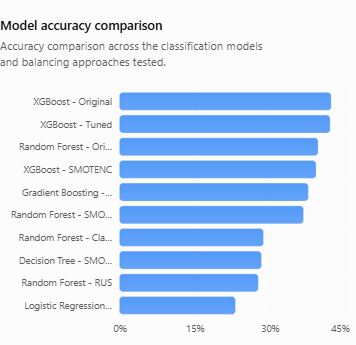

### Comparing Multiple Evaluation Metrics

Calculate accuracy, weighted precision, weighted recall, and weighted F1-score for each model listed in the notebook, then sort the results by accuracy.

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

results = []

def add_metrics(model_name, y_true, y_pred):
    results.append({
        "Model": model_name,
        "Accuracy (%)": round(accuracy_score(y_true, y_pred) * 100, 2),
        "Precision (%)": round(precision_score(y_true, y_pred, average="weighted", zero_division=0) * 100, 2),
        "Recall (%)": round(recall_score(y_true, y_pred, average="weighted", zero_division=0) * 100, 2),
        "F1-score (%)": round(f1_score(y_true, y_pred, average="weighted", zero_division=0) * 100, 2)
    })

# 1. Logistic Regression - SMOTENC
add_metrics(
    "Logistic Regression - SMOTENC",
    y_test,
    log_model.predict(X_test_smote)
)

# 2. Decision Tree - SMOTENC
add_metrics(
    "Decision Tree - SMOTENC",
    y_test,
    dt_model.predict(X_test_smote)
)

# 3. Random Forest - SMOTENC
add_metrics(
    "Random Forest - SMOTENC",
    y_test,
    rf_model.predict(X_test_smote)
)

# 4. Gradient Boosting - SMOTENC
add_metrics(
    "Gradient Boosting - SMOTENC",
    y_test,
    gb_model.predict(X_test_smote)
)

# 5. Random Forest - Original
add_metrics(
    "Random Forest - Original",
    y_test,
    rf_original.predict(X_test_processed)
)

# 6. Random Forest - RUS
add_metrics(
    "Random Forest - RUS",
    y_test,
    rf_rus.predict(X_test_smote)
)

# 7. Random Forest - Class Weighted
add_metrics(
    "Random Forest - Class Weighted",
    y_test,
    rf_weighted.predict(X_test_smote)
)

# 8. XGBoost - Original
add_metrics(
    "XGBoost - Original",
    y_test_xgb,
    xgb_model.predict(X_test_processed)
)

# 9. XGBoost - Tuned
add_metrics(
    "XGBoost - Tuned",
    y_test_xgb,
    xgb_tuned.predict(X_test_processed)
)

# 10. XGBoost - SMOTENC
add_metrics(
    "XGBoost - SMOTENC",
    y_test_xgb,
    xgb_smote.predict(X_test_smote)
)

model_metrics = pd.DataFrame(results)
model_metrics = model_metrics.sort_values(
    by="Accuracy (%)",
    ascending=False
).reset_index(drop=True)

print(model_metrics.to_string(index=False))

                         Model  Accuracy (%)  Precision (%)  Recall (%)  F1-score (%)
            XGBoost - Original         42.02          40.04       42.02         38.02
               XGBoost - Tuned         41.81          39.65       41.81         37.73
      Random Forest - Original         39.41          37.09       39.41         34.08
             XGBoost - SMOTENC         39.01          37.40       39.01         36.55
   Gradient Boosting - SMOTENC         37.47          36.03       37.47         35.24
       Random Forest - SMOTENC         36.50          35.34       36.50         35.71
Random Forest - Class Weighted         28.51          38.79       28.51         28.72
       Decision Tree - SMOTENC         28.11          29.74       28.11         28.80
           Random Forest - RUS         27.49          36.54       27.49         28.07
 Logistic Regression - SMOTENC         22.92          30.34       22.92         24.61


### Displaying the Final Metrics Table

Display the `model_metrics` dataframe created in the previous cell.

In [ ]:
# Final Model Performance Comparison

model_metrics

,Model,Accuracy (%),Precision (%),Recall (%),F1-score (%)
0,XGBoost - Original,42.02,40.04,42.02,38.02
1,XGBoost - Tuned,41.81,39.65,41.81,37.73
2,Random Forest - Original,39.41,37.09,39.41,34.08
3,XGBoost - SMOTENC,39.01,37.40,39.01,36.55
4,Gradient Boosting - SMOTENC,37.47,36.03,37.47,35.24
5,Random Forest - SMOTENC,36.50,35.34,36.50,35.71
6,Random Forest - Class Weighted,28.51,38.79,28.51,28.72
7,Decision Tree - SMOTENC,28.11,29.74,28.11,28.80
8,Random Forest - RUS,27.49,36.54,27.49,28.07
9,Logistic Regression - SMOTENC,22.92,30.34,22.92,24.61


### Final XGBoost Evaluation

Generate the original XGBoost model's accuracy and classification report using the encoded test labels.

In [ ]:
from sklearn.metrics import accuracy_score, classification_report

y_pred_xgb = xgb_model.predict(X_test_processed)

print("Accuracy:", accuracy_score(y_test_xgb, y_pred_xgb))
print("\nClassification Report:")
print(classification_report(
    y_test_xgb,
    y_pred_xgb,
    target_names=label_encoder.classes_
))

Accuracy: 0.42017334505715365

Classification Report:
                    precision    recall  f1-score   support

              0-10       0.40      0.12      0.18      4721
             11-20       0.43      0.50      0.46     15628
             21-30       0.42      0.67      0.52     17498
             31-40       0.43      0.21      0.28     11032
             41-50       0.00      0.00      0.00      2349
             51-60       0.40      0.51      0.45      7004
             61-70       0.00      0.00      0.00       549
             71-80       0.32      0.01      0.01      2051
             81-90       0.37      0.18      0.24       967
            91-100       0.67      0.00      0.01       553
More than 100 Days       0.52      0.44      0.48      1336

          accuracy                           0.42     63688
         macro avg       0.36      0.24      0.24     63688
      weighted avg       0.40      0.42      0.38     63688



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


# Challenges Faced

Challenges Faced:

1. The target variable Stay contains 11 different classes, making this a multiclass classification problem.

2. The target classes are highly imbalanced. Some Stay categories have considerably fewer observations than the major classes.

3. Missing values were present in Bed_Grade and City_Code_Patient and were handled using the respective mode values.

4. Some incorrect values such as "Nov-20" were present in the Age and Stay columns and were corrected during data cleaning.

5. Several categorical/code-based features required appropriate encoding before applying machine learning algorithms.

6. Different class-balancing techniques were tested, including SMOTENC, Random Under-Sampling and class-weighted Random Forest. These methods did not improve the final accuracy compared with the original training data.

7. Some machine learning models showed overfitting. For example, Random Forest achieved very high training accuracy but considerably lower test accuracy.

8. Computational resources were also a challenge because some models became expensive to train on the large dataset, particularly after oversampling.

# Final conclusion

Conclusion:

The objective of this project was to predict the length of hospital stay based on patient and hospital-related factors.

After data cleaning, exploratory data analysis, feature preprocessing and model comparison, several classification algorithms were evaluated.

Among the tested models, XGBoost trained on the original preprocessed dataset achieved the highest test accuracy of 42.02%. The tuned XGBoost model achieved 41.81%, while Random Forest on the original data achieved 39.41%.

Different class-balancing techniques were also evaluated. However, SMOTENC, Random Under-Sampling and class-weighted Random Forest did not improve the performance compared with the original training data.

The XGBoost model also showed that Ward Type and Visitors with Patient were among the most influential features for predicting hospital stay.

Overall, XGBoost with the original preprocessed dataset was selected as the best-performing model among the approaches tested, with an accuracy of 42.02%. The results also indicate that predicting all 11 hospital-stay categories is challenging, particularly for classes with fewer observations.

### Notebook End

This cell is empty and does not execute any code.